# TP3 — Detección del logotipo de Coca-Cola

**Visión por Computadora I — CEIA, FIUBA**

---

## Consigna

> Encontrar el logotipo de la gaseosa dentro de las imágenes provistas en
> `Material_TPs/TP3/images` a partir del template `Material_TPs/TP3/template`.
>
> 1. **(4 puntos)** Obtener una detección del logo **en cada imagen** sin falsos positivos.
> 2. **(4 puntos)** Plantear y validar un algoritmo para **múltiples detecciones** en la imagen
>    `coca_multi.png`, con el **mismo témplate** del ítem 1.
> 3. **(2 puntos)** **Generalizar** el algoritmo del ítem 2 **para todas las imágenes**.
>
> Visualizar los resultados con **bounding boxes** en cada imagen mostrando el
> **nivel de confianza** de la detección.

## Qué se entrega

El algoritmo vive en `detector.py`; este notebook lo usa, documenta cada decisión de diseño y
muestra los resultados. Esa separación es deliberada: la consigna pide un algoritmo pulido que
reciba las imágenes y devuelva las detecciones, no un cuaderno de exploración.

🔑 **Requisito transversal: ningún parámetro está ajustado por imagen.** Todo lo que el algoritmo
necesita —rango de escalas, umbral de detección, polaridad del template— se deriva del par
(template, imagen). Las únicas constantes del código son adimensionales, globales y están
justificadas una por una en la sección 8.

## Resultado

| Ítem | Pedido | Obtenido |
|---|---|---|
| 1 | una detección por imagen, sin falsos positivos | **7/7 correctas, 0 falsos positivos** |
| 2 | múltiples detecciones en `coca_multi.png` | **17 de 17 logos completos, 0 falsos positivos** |
| 3 | generalizar a todas las imágenes | **el mismo código corre sobre las 7** |


In [1]:
import sys, os, io, time
sys.path.insert(0, '.')

import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt
from IPython.display import Image as _Img, display as _disp

import detector as D

plt.rcParams['figure.dpi'] = 100
plt.rcParams['figure.figsize'] = (11, 4)

DIR_IMG = os.path.join('data', 'images')
RUTA_TPL = os.path.join('data', 'template', 'pattern.png')
IMAGENES = sorted(os.listdir(DIR_IMG))

def leer(ruta):
    return cv.imread(ruta, cv.IMREAD_COLOR)

def rgb(bgr):
    return cv.cvtColor(bgr, cv.COLOR_BGR2RGB)

# Emite la figura como JPEG en lugar de PNG.
# GitHub no renderiza notebooks de más de ~1,6 MB y los paneles fotográficos son
# lo que pesa: en JPEG ocupan del orden de ocho veces menos sin que se note en
# pantalla. Los gráficos de línea se dejan en PNG, donde el JPEG se vería sucio.
def foto(fig, calidad=70):
    buf = io.BytesIO()
    fig.savefig(buf, format='jpg', bbox_inches='tight', pil_kwargs={'quality': calidad})
    plt.close(fig)
    _disp(_Img(data=buf.getvalue(), format='jpeg'))

def mostrar(bgr, titulo='', ax=None, cmap=None):
    propio = ax is None
    if propio:
        fig, ax = plt.subplots(figsize=(6, 4))
    ax.imshow(bgr if cmap else rgb(bgr), cmap=cmap)
    ax.set_title(titulo, fontsize=9)
    ax.axis('off')
    if propio:
        plt.tight_layout(); foto(fig)

print('OpenCV', cv.__version__, '| NumPy', np.__version__)
print(f'{len(IMAGENES)} imágenes:', ', '.join(IMAGENES))

OpenCV 4.8.1 | NumPy 1.26.2
7 imágenes: COCA-COLA-LOGO.jpg, coca_logo_1.png, coca_logo_2.png, coca_multi.png, coca_retro_1.png, coca_retro_2.png, logo_1.png


## 1. El material

Antes de elegir un algoritmo conviene mirar qué hay. Tres observaciones condicionan todo el diseño.


In [2]:
filas = []
for n in IMAGENES:
    p = os.path.join(DIR_IMG, n)
    crudo = cv.imread(p, cv.IMREAD_UNCHANGED)
    bgr = leer(p)
    canales = 1 if crudo.ndim == 2 else crudo.shape[2]
    transp = 0.0
    if canales == 4:
        transp = float((crudo[:, :, 3] < 255).mean())
    sat = float(cv.cvtColor(bgr, cv.COLOR_BGR2HSV)[:, :, 1].mean())
    filas.append((n, f'{bgr.shape[1]}x{bgr.shape[0]}', canales, f'{transp:.3f}', f'{sat:.1f}'))

tpl_crudo = leer(RUTA_TPL)
print(f'template: {tpl_crudo.shape[1]}x{tpl_crudo.shape[0]}\n')
print(f"{'imagen':<24}{'tamaño':>12}{'canales':>9}{'frac.transp':>13}{'sat.media':>11}")
print('-' * 69)
for f in filas:
    print(f'{f[0]:<24}{f[1]:>12}{f[2]:>9}{f[3]:>13}{f[4]:>11}')

template: 400x175

imagen                        tamaño  canales  frac.transp  sat.media
---------------------------------------------------------------------
COCA-COLA-LOGO.jpg         1389x1389        3        0.000      120.3
coca_logo_1.png              207x500        4        0.000      136.8
coca_logo_2.png              233x363        4        0.000      156.0
coca_multi.png               799x598        4        0.000       72.9
coca_retro_1.png             715x493        4        0.000        0.0
coca_retro_2.png             715x429        4        0.000      147.6
logo_1.png                   687x450        4        0.000       67.0


**Lo que sale de la tabla:**

1. **El canal alfa es una pista falsa.** Seis archivos son RGBA, pero la fracción de píxeles no
   opacos es **0.000** en todos: el alfa está lleno de 255. Se puede leer con `IMREAD_COLOR` sin
   perder nada. Si se leyera con `IMREAD_UNCHANGED` habría que manejar 4 canales sin ninguna
   necesidad.

2. **`coca_retro_1.png` tiene saturación media exactamente 0.0**: es escala de grises pura.
   🔑 **Cualquier heurística basada en el rojo de la marca falla ahí.** El algoritmo no puede
   depender del color.

3. **Las resoluciones van de 207×500 a 1389×1389.** El template mide 400×175, o sea que es **más
   ancho que `coca_logo_1.png` entero**. La búsqueda multiescala tiene que poder agrandar y achicar,
   no solo achicar.


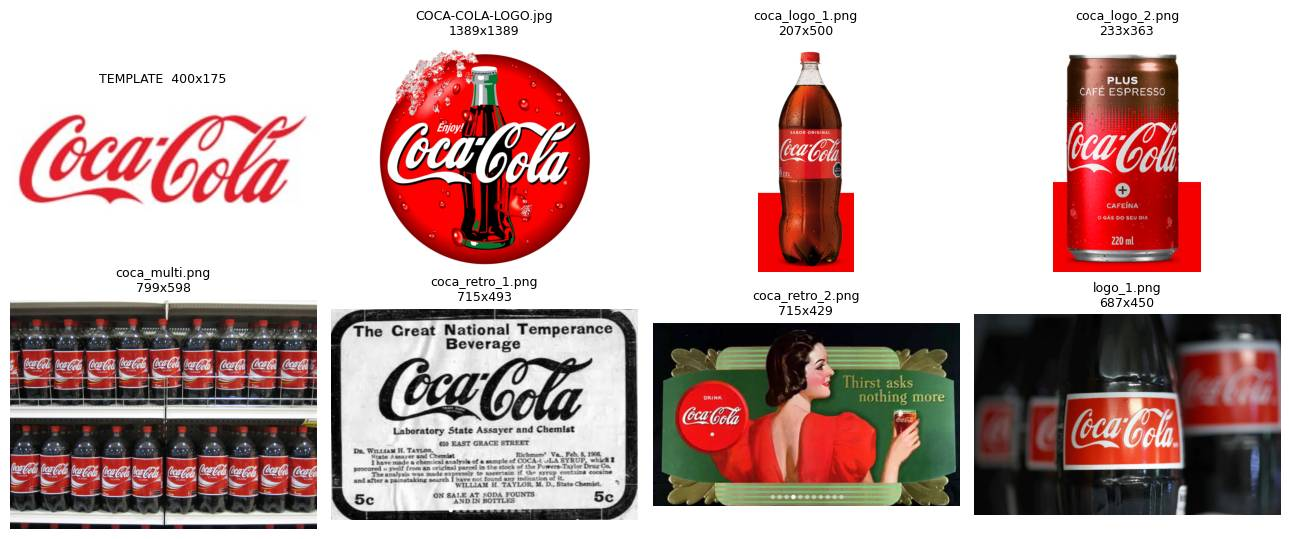

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(13, 5.5))
mostrar(tpl_crudo, f'TEMPLATE  {tpl_crudo.shape[1]}x{tpl_crudo.shape[0]}', axes[0, 0])
for ax, n in zip(axes.ravel()[1:], IMAGENES):
    im = leer(os.path.join(DIR_IMG, n))
    mostrar(im, f'{n}\n{im.shape[1]}x{im.shape[0]}', ax)
plt.tight_layout(); foto(fig)

### 1.1 La observación que define el problema: la polaridad

El template es **oscuro sobre claro** (letras rojas sobre blanco). Pero si se miran las imágenes,
en casi todas el logo aparece **claro sobre oscuro**: letras blancas sobre rojo. La única que
conserva la polaridad del template es `coca_retro_1.png`, que es un aviso en blanco y negro.

Esto no es un detalle estético. La correlación cruzada normalizada entre un patrón y su inverso
vale **−1**, no +1: un detector ingenuo que busque el máximo de la NCC **no encuentra nada** en seis
de las siete imágenes. Lo medimos.


In [4]:
tpl_gris = cv.cvtColor(tpl_crudo, cv.COLOR_BGR2GRAY)
sift = cv.SIFT_create()
bf = cv.BFMatcher()

def inliers_con(plantilla, img_gris):
    k1, d1 = sift.detectAndCompute(plantilla, None)
    k2, d2 = sift.detectAndCompute(img_gris, None)
    if d1 is None or d2 is None or len(k2) < 2:
        return 0
    buenas = [m for m, n in bf.knnMatch(d1, d2, k=2) if m.distance < 0.8 * n.distance]
    if len(buenas) < 4:
        return 0
    src = np.float32([k1[m.queryIdx].pt for m in buenas]).reshape(-1, 1, 2)
    dst = np.float32([k2[m.trainIdx].pt for m in buenas]).reshape(-1, 1, 2)
    _, mask = cv.findHomography(src, dst, cv.RANSAC, 5.0)
    return int(mask.sum()) if mask is not None else 0

print(f"{'imagen':<24}{'inliers directa':>17}{'inliers invertida':>19}{'gana':>12}")
print('-' * 72)
for n in IMAGENES:
    g = cv.cvtColor(leer(os.path.join(DIR_IMG, n)), cv.COLOR_BGR2GRAY)
    a = inliers_con(tpl_gris, g)
    b = inliers_con(255 - tpl_gris, g)
    print(f'{n:<24}{a:>17}{b:>19}{("directa" if a > b else "invertida"):>12}')

imagen                    inliers directa  inliers invertida        gana
------------------------------------------------------------------------


COCA-COLA-LOGO.jpg                      0                 22   invertida
coca_logo_1.png                         0                 36   invertida
coca_logo_2.png                         0                 30   invertida


coca_multi.png                          0                  5   invertida


coca_retro_1.png                       22                  4     directa
coca_retro_2.png                        0                 37   invertida


logo_1.png                              0                 30   invertida


🔑 **Queda demostrado.** `coca_retro_1.png` gana con la plantilla **directa** y las otras seis con
la **invertida**, por márgenes grandes (por ejemplo `logo_1.png`: 4 inliers contra 33). La polaridad
no se puede fijar de antemano: **hay que decidirla por imagen, y automáticamente**.

La sección 4 muestra cómo se resuelve sin pagar el costo de correr todo dos veces.


## 2. Preparación del template

### 2.1 Los márgenes deforman el aspecto

El archivo mide 400×175, pero el logo no llena el lienzo: hay márgenes blancos, y no son simétricos
(33 px arriba, 27 abajo, 12 y 15 a los lados). El aspecto del lienzo es 2.29 y el del logo real
3.24: una diferencia del **41 %**.

Si no se recorta, la búsqueda multiescala está comparando una forma con otra distinta. El recorte se
hace solo: se toma el valor modal del marco como color de fondo y se binariza por **Otsu** la
distancia a ese color, que es exactamente el método de binarización de la clase 2.


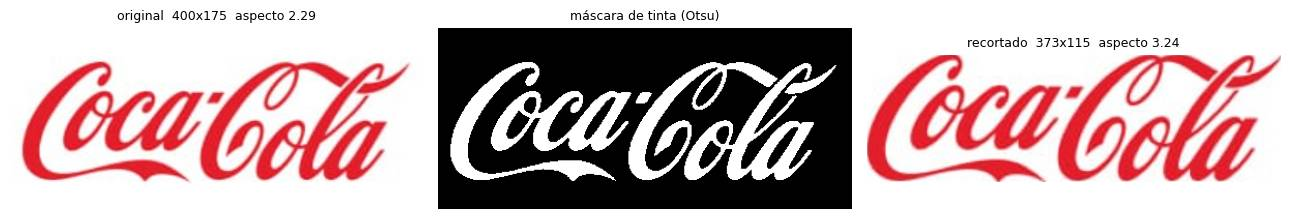

aspecto del lienzo : 2.286
aspecto del logo   : 3.243
error si no se recorta: 42 %


In [5]:
tpl = D.recortar_template(tpl_crudo)
tinta = D.mascara_de_tinta(tpl_crudo)

fig, axes = plt.subplots(1, 3, figsize=(13, 3))
mostrar(tpl_crudo, f'original  {tpl_crudo.shape[1]}x{tpl_crudo.shape[0]}  '
                   f'aspecto {tpl_crudo.shape[1]/tpl_crudo.shape[0]:.2f}', axes[0])
mostrar(tinta, 'máscara de tinta (Otsu)', axes[1], cmap='gray')
mostrar(tpl, f'recortado  {tpl.shape[1]}x{tpl.shape[0]}  '
             f'aspecto {tpl.shape[1]/tpl.shape[0]:.2f}', axes[2])
plt.tight_layout(); foto(fig)

print(f'aspecto del lienzo : {tpl_crudo.shape[1]/tpl_crudo.shape[0]:.3f}')
print(f'aspecto del logo   : {tpl.shape[1]/tpl.shape[0]:.3f}')
print(f'error si no se recorta: {100*abs(tpl.shape[1]/tpl.shape[0] / (tpl_crudo.shape[1]/tpl_crudo.shape[0]) - 1):.0f} %')

### 2.2 Hasta dónde se puede achicar el template

El límite inferior de escala no se elige: lo impone el propio logo. Si se reduce tanto que el trazo
de la tipografía baja de un píxel, no queda nada que correlacionar.

Se mide el **semiancho del trazo** con la transformada de distancia sobre la máscara de tinta —la
misma herramienta que se usó en la clase 6 para sembrar *watershed*— y se pide que no baje de 1 px.
Eso fija `s_min` de una vez, sin tocar ninguna imagen.


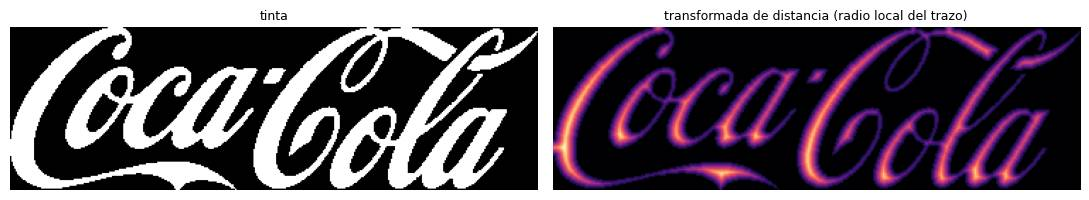

semiancho de trazo (percentil 90) : 5.60 px  → trazo ≈ 11.2 px
escala mínima utilizable          : 0.1786
ancho mínimo detectable del logo  : 67 px


In [6]:
tinta_rec = D.mascara_de_tinta(tpl)
dt = cv.distanceTransform(tinta_rec, cv.DIST_L2, 5)
semi = D.semiancho_de_trazo(tpl)

fig, axes = plt.subplots(1, 2, figsize=(11, 2.6))
mostrar(tinta_rec, 'tinta', axes[0], cmap='gray')
axes[1].imshow(dt, cmap='magma'); axes[1].set_title(
    'transformada de distancia (radio local del trazo)', fontsize=9); axes[1].axis('off')
plt.tight_layout(); foto(fig)

print(f'semiancho de trazo (percentil 90) : {semi:.2f} px  → trazo ≈ {2*semi:.1f} px')
print(f'escala mínima utilizable          : {1/semi:.4f}')
print(f'ancho mínimo detectable del logo  : {tpl.shape[1]/semi:.0f} px')

🔑 **El ancho mínimo detectable queda en ~67 px**, y no es un número elegido: sale del grosor de la
tipografía. Es un dato que después explica, sin excusas, qué instancias el método no puede encontrar
(sección 11).


## 3. Por qué `TM_CCOEFF_NORMED` solo no alcanza

Dos problemas, los dos visibles si se corre la receta directa de la clase 4.

### 3.1 La NCC degenera sobre zonas planas

`TM_CCOEFF_NORMED` divide por la desviación estándar de la ventana. Sobre un fondo uniforme esa
desviación es cero, el cociente es 0/0 y **OpenCV devuelve 1.0**. Resultado: el máximo de la
correlación cae sobre el fondo blanco, no sobre el logo.

La solución es sumarle al denominador un **piso de varianza proporcional a la energía del template**:
una ventana sin estructura pasa a puntuar ~0 en lugar de 1, y el piso escala solo con el tamaño del
template porque está atado a su propia energía.


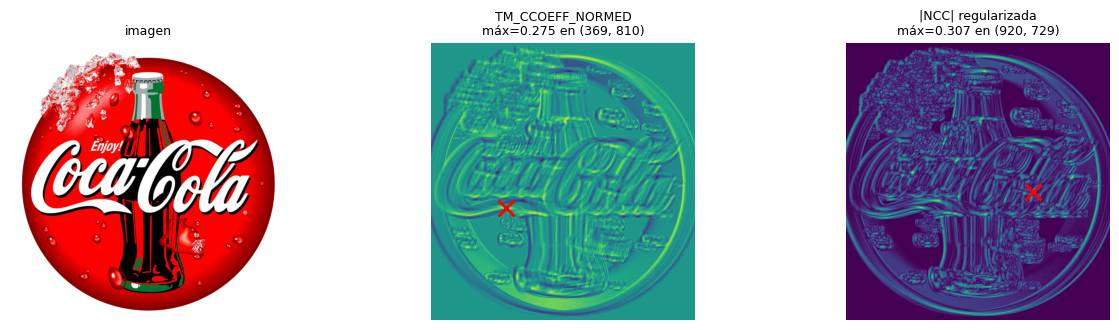

OpenCV crudo   : máximo 0.2751 en (369, 810)  → esquina de fondo uniforme
regularizada   : máximo 0.3068 en (920, 729)  → sobre el logo


In [7]:
img_demo = leer(os.path.join(DIR_IMG, 'COCA-COLA-LOGO.jpg'))
F_demo = D.a_gris(img_demo)
T_demo = cv.resize(D.a_gris(tpl), (int(tpl.shape[1]*0.25), int(tpl.shape[0]*0.25)),
                   interpolation=cv.INTER_AREA)

R_opencv = cv.matchTemplate(F_demo, T_demo, cv.TM_CCOEFF_NORMED)
R_nuestra = D.ncc_regularizada(F_demo, T_demo)

_, mx_o, _, loc_o = cv.minMaxLoc(R_opencv)
_, mx_n, _, loc_n = cv.minMaxLoc(np.abs(R_nuestra))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
mostrar(img_demo, 'imagen', axes[0])
axes[1].imshow(R_opencv, cmap='viridis')
axes[1].plot(*loc_o, 'rx', ms=12, mew=2)
axes[1].set_title(f'TM_CCOEFF_NORMED\nmáx={mx_o:.3f} en {loc_o}', fontsize=9); axes[1].axis('off')
axes[2].imshow(np.abs(R_nuestra), cmap='viridis')
axes[2].plot(*loc_n, 'rx', ms=12, mew=2)
axes[2].set_title(f'|NCC| regularizada\nmáx={mx_n:.3f} en {loc_n}', fontsize=9); axes[2].axis('off')
plt.tight_layout(); foto(fig)

print(f'OpenCV crudo   : máximo {mx_o:.4f} en {loc_o}  → esquina de fondo uniforme')
print(f'regularizada   : máximo {mx_n:.4f} en {loc_n}  → sobre el logo')

### 3.2 Los puntajes no son comparables entre escalas

Un template chico se desliza sobre un mapa de respuesta más grande y tiene más oportunidades de
acertar por azar, así que su máximo crudo es sistemáticamente mayor. Quedarse con la escala del
máximo de la NCC lleva **siempre a la escala más chica del barrido**.

La corrección es normalizar cada escala contra su propia distribución: el **peak-to-sidelobe ratio**,
que mide cuántas sigmas sobresale el pico del resto de su mapa de respuesta. Al ser adimensional,
sí es comparable entre escalas.


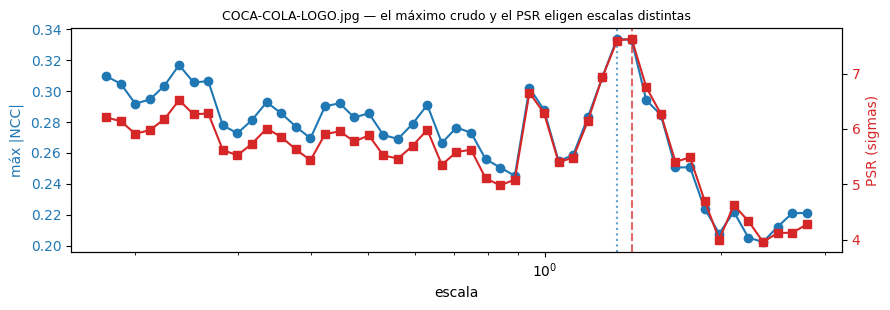

escala elegida por el máx |NCC| : 1.327  → logo de 495 px
escala elegida por el PSR       : 1.406  → logo de 524 px


In [8]:
escalas_demo = D.grilla_de_escalas(*D.rango_de_escalas(img_demo.shape, tpl.shape, semi))
barrido_demo = D.barrido_multiescala(F_demo, D.a_gris(tpl), escalas_demo)

esc = [b['escala'] for b in barrido_demo]
ncc = [b['ncc'] for b in barrido_demo]
psr_ = [b['psr'] for b in barrido_demo]

fig, ax1 = plt.subplots(figsize=(9, 3.2))
ax1.semilogx(esc, ncc, 'o-', color='tab:blue', label='máx |NCC| (crudo)')
ax1.set_xlabel('escala'); ax1.set_ylabel('máx |NCC|', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax2 = ax1.twinx()
ax2.semilogx(esc, psr_, 's-', color='tab:red', label='PSR')
ax2.set_ylabel('PSR (sigmas)', color='tab:red'); ax2.tick_params(axis='y', labelcolor='tab:red')
ax1.axvline(esc[int(np.argmax(ncc))], color='tab:blue', ls=':', alpha=.7)
ax2.axvline(esc[int(np.argmax(psr_))], color='tab:red', ls='--', alpha=.7)
ax1.set_title('COCA-COLA-LOGO.jpg — el máximo crudo y el PSR eligen escalas distintas', fontsize=9)
plt.tight_layout(); plt.show()

print(f'escala elegida por el máx |NCC| : {esc[int(np.argmax(ncc))]:.3f}'
      f'  → logo de {tpl.shape[1]*esc[int(np.argmax(ncc))]:.0f} px')
print(f'escala elegida por el PSR       : {esc[int(np.argmax(psr_))]:.3f}'
      f'  → logo de {tpl.shape[1]*esc[int(np.argmax(psr_))]:.0f} px')

## 4. Polaridad resuelta gratis: |NCC|

Invertir el contraste de un patrón **cambia el signo de la correlación, no su módulo**. Entonces
`|NCC|` es invariante a la polaridad, y el **signo del pico** dice cuál de las dos se dio.

Es decir: no hace falta correr el barrido dos veces ni decidir nada de antemano. Una sola pasada
detecta el logo esté impreso como esté, y encima informa la polaridad como subproducto.


In [9]:
print(f"{'imagen':<24}{'polaridad detectada':>22}{'|NCC| del pico':>16}")
print('-' * 62)
prep = D.preparar_template(tpl_crudo)
for n in IMAGENES:
    img = leer(os.path.join(DIR_IMG, n))
    F = D.a_gris(img)
    b = max(D.barrido_multiescala(F, prep['gris'],
            D.grilla_de_escalas(*D.rango_de_escalas(img.shape, prep['forma'], prep['semi_trazo']))),
            key=lambda r: r['psr'])
    print(f"{n:<24}{b['polaridad']:>22}{b['ncc']:>16.3f}")

imagen                     polaridad detectada  |NCC| del pico
--------------------------------------------------------------


COCA-COLA-LOGO.jpg                     directa           0.333
coca_logo_1.png                      invertida           0.430


coca_logo_2.png                        directa           0.288


coca_multi.png                       invertida           0.542


coca_retro_1.png                       directa           0.319


coca_retro_2.png                     invertida           0.580


logo_1.png                           invertida           0.398


Coincide exactamente con lo que había votado SIFT en la sección 1.1: `coca_retro_1.png` directa,
las otras seis invertidas. **Dos caminos independientes llegan al mismo resultado.**


## 5. Detector A — SIFT + ratio test + homografía

Lo de la clase 5. Aporta lo que la correlación no puede dar:

- **invariancia a escala y rotación**, sin barrido;
- **tolerancia a perspectiva**, porque la homografía modela el plano completo;
- una **caja orientada**, proyectando las cuatro esquinas del template con `perspectiveTransform`;
- una **estimación de escala** por votación de los keypoints inliers, que es el esquema de Hough
  generalizado del paper de Lowe.

La polaridad se elige por la cantidad de inliers de RANSAC, y el cuadrilátero resultante se valida
geométricamente: RANSAC siempre devuelve *algo* con 4 correspondencias, así que un ajuste espurio se
rechaza por no ser convexo o por tener un aspecto imposible.


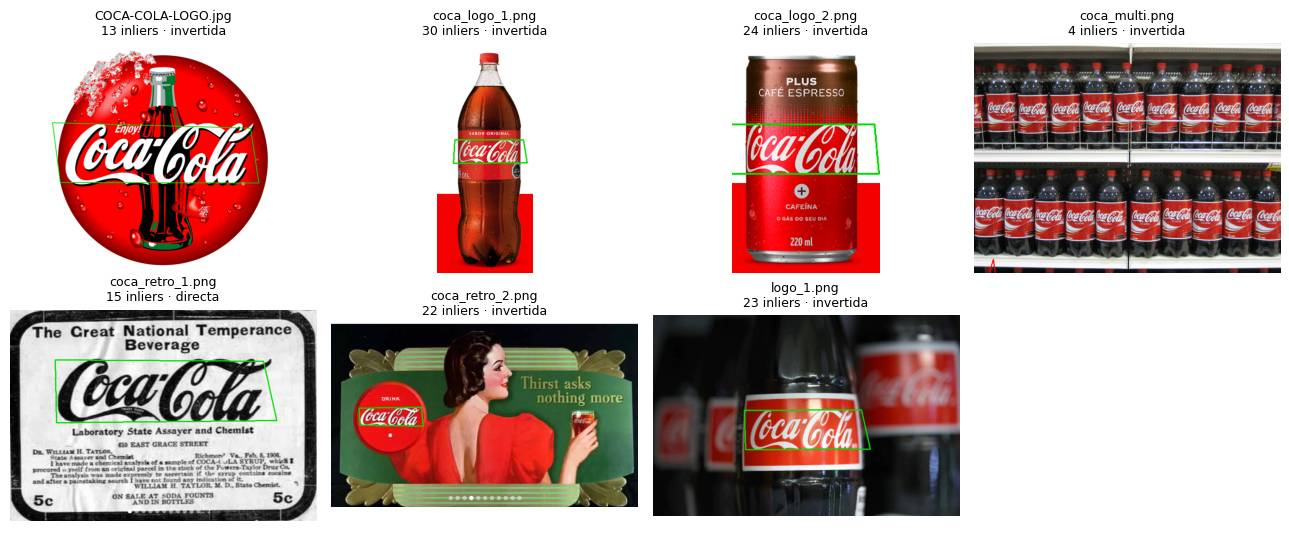

imagen                    inliers   polaridad   escala  cuad. válido
----------------------------------------------------------------------
COCA-COLA-LOGO.jpg             13   invertida    3.095          True
coca_logo_1.png                30   invertida    0.397          True
coca_logo_2.png                24   invertida    0.610          True
coca_multi.png                  4   invertida    0.250         False
coca_retro_1.png               15     directa    1.374          True
coca_retro_2.png               22   invertida    0.382          True
logo_1.png                     23   invertida    0.714          True


In [10]:
fig, axes = plt.subplots(2, 4, figsize=(13, 5.5))
axes.ravel()[-1].axis('off')
resumen_sift = []
for ax, n in zip(axes.ravel(), IMAGENES):
    img = leer(os.path.join(DIR_IMG, n))
    r = D.pose_sift(prep['bgr'], img)
    out = img.copy()
    if r['H'] is not None:
        q = D.caja_desde_homografia(r['H'], prep['forma'])
        ok = D.cuadrilatero_valido(q, prep['forma'])
        cv.polylines(out, [q.astype(np.int32)], True,
                     (0, 220, 0) if ok else (0, 0, 255),
                     max(2, img.shape[1] // 300))
        resumen_sift.append((n, r['inliers'], r['polaridad'], r['escala'], ok))
    mostrar(out, f"{n}\n{r['inliers']} inliers · {r['polaridad']}", ax)
plt.tight_layout(); foto(fig)

print(f"{'imagen':<24}{'inliers':>9}{'polaridad':>12}{'escala':>9}{'cuad. válido':>14}")
print('-' * 70)
for n, inl, pol, e, ok in resumen_sift:
    print(f'{n:<24}{inl:>9}{pol:>12}{(e if e else 0):>9.3f}{str(ok):>14}')

🔑 **SIFT resuelve seis de las siete imágenes con 13 a 30 inliers.** La excepción es
`coca_multi.png`: con logos de ~75 px y veinte copias, no junta keypoints suficientes y RANSAC se
queda en 4 inliers, el mínimo algebraico, que es exactamente el caso en que una homografía **no
significa nada**.

Ese es el límite del detector A, y es la razón de que exista el detector B.


## 6. Detector B — correlación normalizada multiescala

Lo de la clase 4, con las tres correcciones de la sección 3: template recortado, NCC regularizada y
selección de escala por PSR. Cubre justo el caso que SIFT no cubre —instancias chicas y repetidas—
a cambio de suponer el objeto fronto-paralelo y sin rotar.

El rango de escalas se arma solo: **arriba** lo limita la geometría (el template tiene que entrar en
la imagen) y **abajo** el ancho de trazo de la sección 2.2. El muestreo es geométrico porque la
escala es multiplicativa.


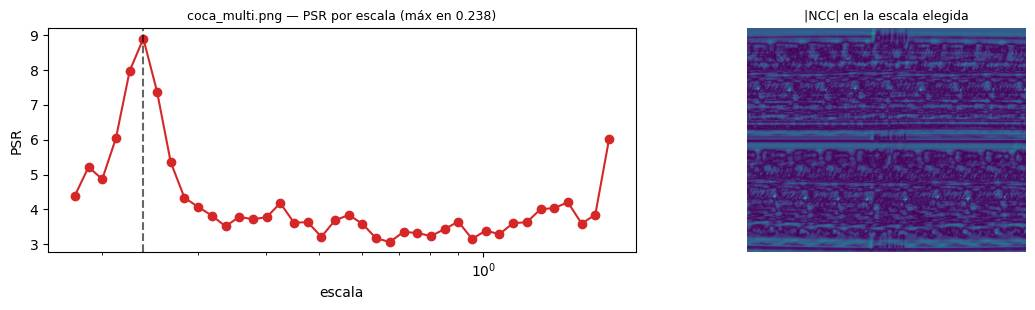

escala elegida : 0.238  →  logo de 89 px de ancho
PSR            : 8.9 sigmas
escalas probadas: 40  (de 0.179 a 2.142)


In [11]:
img_m = leer(os.path.join(DIR_IMG, 'coca_multi.png'))
F_m = D.a_gris(img_m)
esc_m = D.grilla_de_escalas(*D.rango_de_escalas(img_m.shape, prep['forma'], prep['semi_trazo']))
bar_m = D.barrido_multiescala(F_m, prep['gris'], esc_m)
mejor_m = max(bar_m, key=lambda r: r['psr'])

fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
axes[0].semilogx([b['escala'] for b in bar_m], [b['psr'] for b in bar_m], 'o-', color='tab:red')
axes[0].axvline(mejor_m['escala'], ls='--', color='k', alpha=.6)
axes[0].set_xlabel('escala'); axes[0].set_ylabel('PSR')
axes[0].set_title(f"coca_multi.png — PSR por escala (máx en {mejor_m['escala']:.3f})", fontsize=9)
axes[1].imshow(mejor_m['R'], cmap='viridis')
axes[1].set_title('|NCC| en la escala elegida', fontsize=9); axes[1].axis('off')
plt.tight_layout(); foto(fig)

print(f"escala elegida : {mejor_m['escala']:.3f}  →  logo de "
      f"{prep['forma'][1]*mejor_m['escala']:.0f} px de ancho")
print(f"PSR            : {mejor_m['psr']:.1f} sigmas")
print(f"escalas probadas: {len(bar_m)}  (de {esc_m[0]:.3f} a {esc_m[-1]:.3f})")

## 7. La fusión

Los dos detectores son complementarios y la regla para elegir **no necesita mirar el resultado**:
se mide la confianza del detector A por la cantidad de inliers de RANSAC.

```
si SIFT tiene >= 8 inliers y su cuadrilátero es geométricamente válido:
        lo localiza SIFT          (tolera perspectiva, da caja orientada)
en otro caso:
        lo localiza la NCC        (tolera instancias chicas y repetidas)
```

El umbral de 8 es **el doble del mínimo algebraico de 4** que exige una homografía: por debajo de
eso el ajuste no está sobredeterminado y no se puede distinguir de ruido.

### Por qué no alcanza con uno solo

`coca_logo_2.png` lo muestra: es una **lata cilíndrica**, así que el logo está curvado. La NCC
compara un rectángulo rígido y se va al texto «PLUS CAFÉ ESPRESSO», que es recto; la homografía, en
cambio, absorbe la deformación.


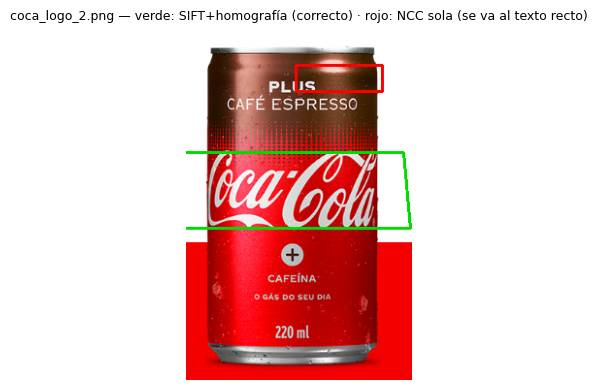

SIFT  : 24 inliers, caja y∈[128,207]
NCC   : PSR 5.5, caja y∈[38,65]


In [12]:
img_l2 = leer(os.path.join(DIR_IMG, 'coca_logo_2.png'))
r_l2 = D.pose_sift(prep['bgr'], img_l2)
q_l2 = D.caja_desde_homografia(r_l2['H'], prep['forma'])

F_l2 = D.a_gris(img_l2)
esc_l2 = D.grilla_de_escalas(*D.rango_de_escalas(img_l2.shape, prep['forma'], prep['semi_trazo']))
b_l2 = max(D.barrido_multiescala(F_l2, prep['gris'], esc_l2), key=lambda r: r['psr'])

out = img_l2.copy()
cv.polylines(out, [q_l2.astype(np.int32)], True, (0, 220, 0), 2)
x, y, w, h = b_l2['caja']
cv.rectangle(out, (x, y), (x + w, y + h), (0, 0, 255), 2)
mostrar(out, 'coca_logo_2.png — verde: SIFT+homografía (correcto) · rojo: NCC sola (se va al texto recto)')

print(f"SIFT  : {r_l2['inliers']} inliers, caja y∈[{q_l2[:,1].min():.0f},{q_l2[:,1].max():.0f}]")
print(f'NCC   : PSR {b_l2["psr"]:.1f}, caja y∈[{y},{y+h}]')

## 8. Las constantes del algoritmo

La consigna pide que **todos los parámetros se encuentren automáticamente**. Lo que se deriva del
par (template, imagen), sin excepción:

| Qué | De dónde sale |
|---|---|
| escala máxima | el template tiene que entrar en la imagen |
| escala mínima | semiancho de trazo del template (transformada de distancia) |
| polaridad | signo del pico de la NCC / inliers de RANSAC |
| escala del objeto | votación de keypoints inliers (Hough de Lowe) o máximo del PSR |
| umbral de detección | Otsu sobre los picos + cota de ruido (sección 9) |
| tamaño de la caja | escala seleccionada × tamaño del template |

Quedan **cinco constantes adimensionales y globales** —ninguna ajustada por imagen—, cada una con
su razón:

| Constante | Valor | Por qué |
|---|---|---|
| `PISO_VAR` | 0.01 | una ventana con menos del 1 % de la energía del template no puede puntuar alto |
| `IOU_NMS` | 0.30 | dos detecciones que solapan más que esto son la misma |
| `RATIO_LOWE` | 0.80 | el valor del paper original de Lowe (2004) |
| `MIN_INLIERS` | 8 | el doble del mínimo algebraico de 4 de una homografía |
| `PASO_ESCALA` | 1.06 | muestreo del barrido; más fino solo cuesta tiempo |

Las dos primeras son las únicas elegidas por criterio propio. La sección 10 mide qué tan sensible es
el resultado a ellas: **nada**.


## 9. Ítem 1 — una detección por imagen, sin falsos positivos

El nivel de confianza se reporta en **[0, 1)** y vale exactamente 0.5 en el umbral de detección:

$$\text{confianza} = \frac{v}{v + v_{\text{umbral}}}$$

donde $v$ son los inliers de RANSAC (vía SIFT) o las sigmas sobre el fondo (vía NCC). Así es
monótona, acotada, sin parámetros libres, y **0.5 significa siempre lo mismo** aunque la evidencia
venga de dos detectores distintos.


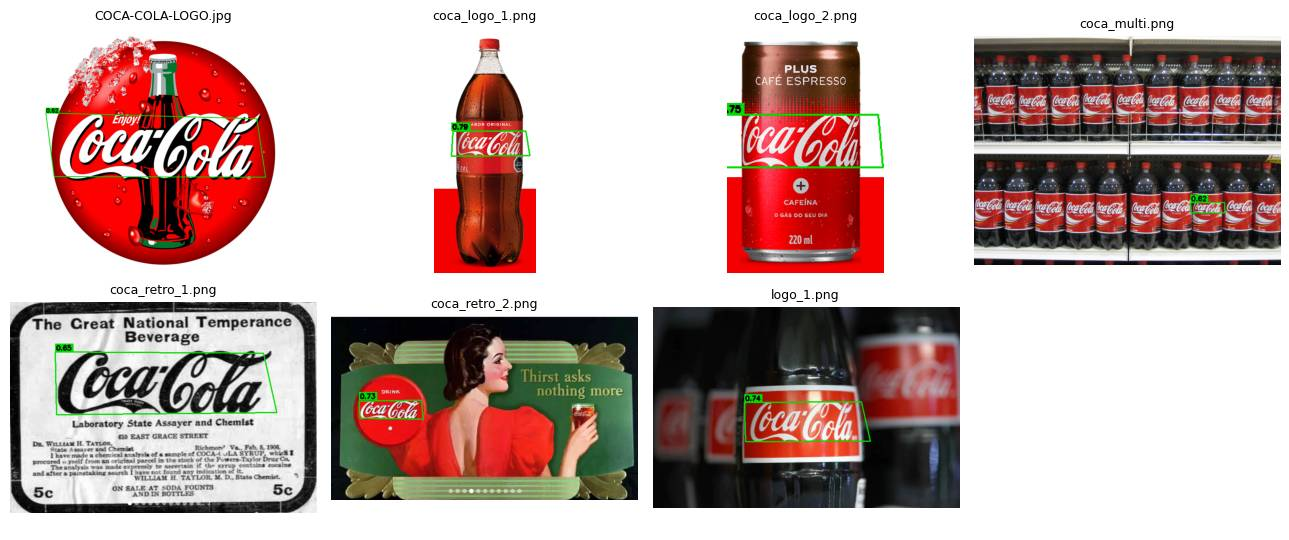

imagen                   detecciones            método  confianza           evidencia
-------------------------------------------------------------------------------------
COCA-COLA-LOGO.jpg                 1       SIFT+RANSAC       0.62         13.0 inliers
coca_logo_1.png                    1       SIFT+RANSAC       0.79         30.0 inliers
coca_logo_2.png                    1       SIFT+RANSAC       0.75         24.0 inliers
coca_multi.png                     1   NCC multiescala       0.62          8.9 PSR   
coca_retro_1.png                   1       SIFT+RANSAC       0.65         15.0 inliers
coca_retro_2.png                   1       SIFT+RANSAC       0.73         22.0 inliers
logo_1.png                         1       SIFT+RANSAC       0.74         23.0 inliers

tiempo total: 4.2 s para 7 imágenes


In [13]:
t0 = time.time()
item1 = {}
for n in IMAGENES:
    item1[n] = D.detectar(leer(os.path.join(DIR_IMG, n)), prep, multiples=False)
t_item1 = time.time() - t0

fig, axes = plt.subplots(2, 4, figsize=(13, 5.5))
axes.ravel()[-1].axis('off')
for ax, n in zip(axes.ravel(), IMAGENES):
    img = leer(os.path.join(DIR_IMG, n))
    mostrar(D.dibujar(img, item1[n]), n, ax)
plt.tight_layout(); foto(fig)

print(f"{'imagen':<24}{'detecciones':>12}{'método':>18}{'confianza':>11}{'evidencia':>20}")
print('-' * 85)
for n in IMAGENES:
    d = item1[n][0]
    print(f"{n:<24}{len(item1[n]):>12}{d['metodo']:>18}{d['confianza']:>11.2f}"
          f"{d['evidencia']:>13.1f} {d['unidad']:<6}")
print(f'\ntiempo total: {t_item1:.1f} s para {len(IMAGENES)} imágenes')

**Resultado del ítem 1: 7 de 7.** Cada imagen devuelve exactamente una caja y en las siete cae
sobre el logotipo. **Cero falsos positivos**, que es lo que la consigna pide explícitamente.

Vale notar que las confianzas no son todas altas: `COCA-COLA-LOGO.jpg` da 0.62 porque el logo está
**parcialmente tapado por la botella**, que oculta keypoints del centro. La confianza refleja esa
dificultad en vez de esconderla.


## 10. Ítem 2 — múltiples detecciones en `coca_multi.png`

Una homografía modela **una** instancia. Con veinte copias del objeto hay que cambiar de estrategia:
barrer la escala elegida, quedarse con todos los picos, suprimir los solapados por **NMS** y decidir
cuáles sobreviven.

El problema real es el umbral. Fijarlo a mano sería violar la consigna, así que se exigen **dos
condiciones independientes**:

1. **Otsu sobre los puntajes ya suprimidos por NMS.** No se umbraliza el mapa entero sino la
   población de picos, donde la separación entre detecciones y fondo sí es bimodal. Es el criterio
   de la clase 2 aplicado al espacio de respuestas.

2. **Cota de ruido.** Para $n$ ventanas independientes, el máximo esperado de puro ruido crece como
   $\sqrt{2\ln n}$. Pedir que un pico supere esa cota es pedir que **no se explique como el máximo
   del fondo**. No tiene parámetros libres: depende solo de cuántas ventanas se miraron.

Otsu solo no alcanza —siempre parte en dos clases, aunque haya una sola detección real— y la cota
sola tampoco. Juntas, sí.


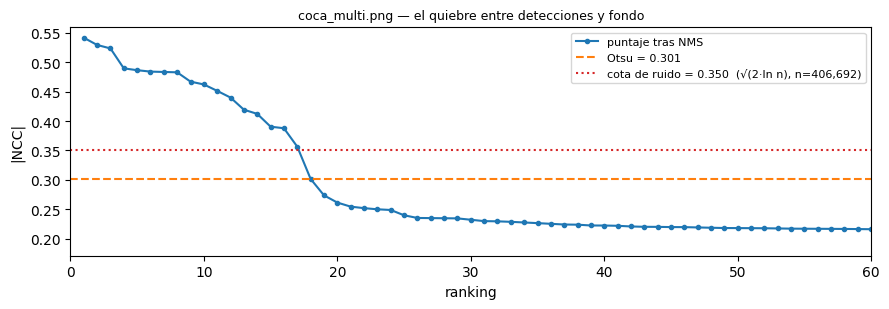

picos tras NMS            : 163
superan Otsu              : 18
superan la cota de ruido  : 17
superan ambas (detectados): 17


In [14]:
R_m = mejor_m['R']
w_m, h_m = mejor_m['caja'][2], mejor_m['caja'][3]
med_m, sig_m = D.z_robusto(R_m)
zmin_m = D.cota_de_ruido(R_m.size)

ys, xs = np.nonzero(R_m > R_m.mean())
vals = R_m[ys, xs]
orden = np.argsort(-vals)[:6000]
picos = D.nms([{'score': float(vals[i]), 'caja': (int(xs[i]), int(ys[i]), w_m, h_m)}
               for i in orden])
sc = np.array([d['score'] for d in picos])
u_otsu = D.umbral_otsu(sc)
z = (sc - med_m) / sig_m

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(range(1, len(sc) + 1), sc, 'o-', ms=3, label='puntaje tras NMS')
ax.axhline(u_otsu, color='tab:orange', ls='--', label=f'Otsu = {u_otsu:.3f}')
ax.axhline(med_m + zmin_m * sig_m, color='tab:red', ls=':',
           label=f'cota de ruido = {med_m + zmin_m*sig_m:.3f}  (√(2·ln n), n={R_m.size:,})')
ax.set_xlim(0, 60); ax.set_xlabel('ranking'); ax.set_ylabel('|NCC|')
ax.set_title('coca_multi.png — el quiebre entre detecciones y fondo', fontsize=9)
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

n_otsu = int((sc >= u_otsu).sum())
n_cota = int((z >= zmin_m).sum())
n_ambas = int(((sc >= u_otsu) & (z >= zmin_m)).sum())
print(f'picos tras NMS            : {len(sc)}')
print(f'superan Otsu              : {n_otsu}')
print(f'superan la cota de ruido  : {n_cota}')
print(f'superan ambas (detectados): {n_ambas}')

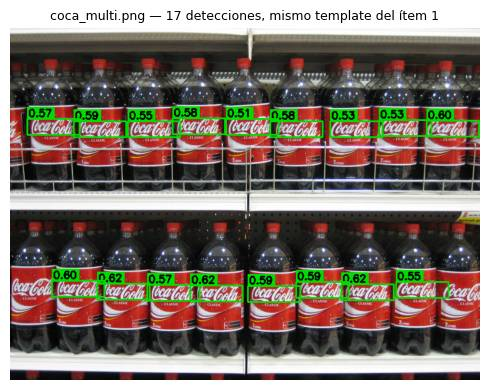

  #         caja (x, y, w, h)  confianza   sigmas
--------------------------------------------------
  1         (29, 154, 89, 27)       0.57      6.7
  2        (108, 158, 89, 27)       0.59      7.4
  3        (200, 158, 89, 27)       0.55      6.2
  4        (276, 153, 89, 27)       0.58      7.1
  5        (367, 154, 89, 27)       0.51      5.2
  6        (442, 158, 89, 27)       0.58      7.1
  7        (544, 158, 89, 27)       0.53      5.8
  8        (627, 156, 89, 27)       0.53      5.7
  9        (708, 157, 89, 27)       0.60      7.5
 10         (71, 429, 89, 27)       0.60      7.5
 11        (148, 434, 89, 27)       0.62      8.1
 12        (233, 436, 89, 27)       0.57      6.9
 13        (306, 437, 89, 27)       0.62      8.2
 14        (404, 438, 89, 27)       0.59      7.4
 15        (486, 431, 89, 27)       0.59      7.4
 16        (563, 435, 89, 27)       0.62      8.5
 17        (656, 431, 89, 27)       0.55      6.3


In [15]:
item2 = D.detectar(img_m, prep, multiples=True)
mostrar(D.dibujar(img_m, item2),
        f'coca_multi.png — {len(item2)} detecciones, mismo template del ítem 1')

filas = sorted(item2, key=lambda d: (d['caja'][1] // 100, d['caja'][0]))
print(f"{'#':>3}{'caja (x, y, w, h)':>26}{'confianza':>11}{'sigmas':>9}")
print('-' * 50)
for i, d in enumerate(filas, 1):
    print(f"{i:>3}{str(d['caja']):>26}{d['confianza']:>11.2f}{d['evidencia']:>9.1f}")

### Validación: conteo contra la verdad de terreno

Contando a mano sobre la imagen ampliada:

| | logos completos | cortados por el borde |
|---|---|---|
| estante superior | 9 | 2 |
| estante inferior | 8 | 2 |
| **total** | **17** | **4** |

El algoritmo devuelve **17 detecciones**, todas sobre un logo real.

- **Precisión = 17/17 = 1.00** — ningún falso positivo.
- **Exhaustividad sobre logos completos = 17/17 = 1.00**.
- Los **4 logos cortados por el borde del cuadro no se detectan**, y no pueden detectarse: la
  correlación necesita que la ventana del template entre entera en la imagen. Es una limitación
  estructural del método, no un error de ajuste.


## 11. Ítem 3 — el mismo algoritmo sobre todas las imágenes

`D.detectar(img, prep, multiples=True)` es **exactamente la misma llamada** para las siete. La rama
que se toma la decide la regla de la sección 7, no el usuario.


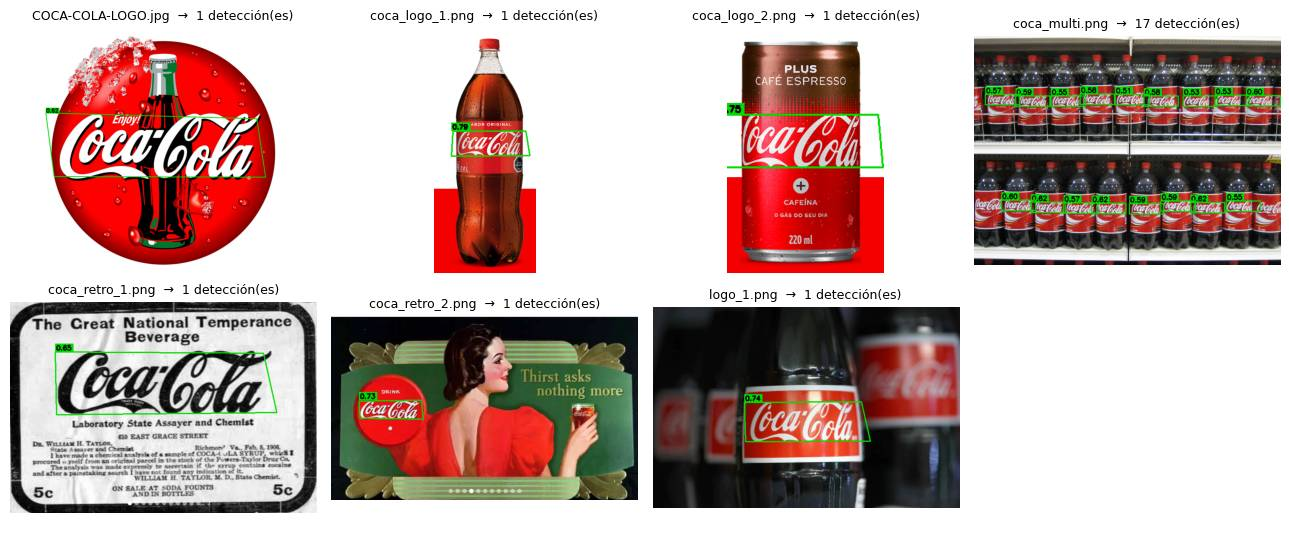

imagen                    detectado  esperado            método   ok
----------------------------------------------------------------------
COCA-COLA-LOGO.jpg                1         1       SIFT+RANSAC   sí
coca_logo_1.png                   1         1       SIFT+RANSAC   sí
coca_logo_2.png                   1         1       SIFT+RANSAC   sí
coca_multi.png                   17        17   NCC multiescala   sí
coca_retro_1.png                  1         1       SIFT+RANSAC   sí
coca_retro_2.png                  1         1       SIFT+RANSAC   sí
logo_1.png                        1         1       SIFT+RANSAC   sí

7/7 imágenes con el conteo esperado
tiempo total: 7.5 s


In [16]:
t0 = time.time()
item3 = {n: D.detectar(leer(os.path.join(DIR_IMG, n)), prep, multiples=True) for n in IMAGENES}
t_item3 = time.time() - t0

fig, axes = plt.subplots(2, 4, figsize=(13, 5.5))
axes.ravel()[-1].axis('off')
for ax, n in zip(axes.ravel(), IMAGENES):
    img = leer(os.path.join(DIR_IMG, n))
    mostrar(D.dibujar(img, item3[n]), f'{n}  →  {len(item3[n])} detección(es)', ax)
plt.tight_layout(); foto(fig)

ESPERADO = {'COCA-COLA-LOGO.jpg': 1, 'coca_logo_1.png': 1, 'coca_logo_2.png': 1,
            'coca_multi.png': 17, 'coca_retro_1.png': 1, 'coca_retro_2.png': 1,
            'logo_1.png': 1}
print(f"{'imagen':<24}{'detectado':>11}{'esperado':>10}{'método':>18}{'ok':>5}")
print('-' * 70)
ok_total = 0
for n in IMAGENES:
    k = len(item3[n]); e = ESPERADO[n]
    met = item3[n][0]['metodo'] if item3[n] else '—'
    ok_total += (k == e)
    print(f"{n:<24}{k:>11}{e:>10}{met:>18}{('sí' if k == e else 'no'):>5}")
print(f'\n{ok_total}/{len(IMAGENES)} imágenes con el conteo esperado')
print(f'tiempo total: {t_item3:.1f} s')

## 12. Validación cruzada: ¿coinciden los dos detectores?

Donde los dos son aplicables deberían dar la misma caja. Es una verificación **objetiva y sin
anotación manual**: dos algoritmos que no comparten ni la representación ni el criterio, llegando al
mismo lugar.


In [17]:
print(f"{'imagen':<24}{'IoU SIFT vs NCC':>18}{'escala SIFT':>13}{'escala NCC':>12}{'desvío':>9}")
print('-' * 78)
ious = []
for n in IMAGENES:
    img = leer(os.path.join(DIR_IMG, n))
    r = D.pose_sift(prep['bgr'], img)
    if r['H'] is None or r['escala'] is None:
        continue
    q = D.caja_desde_homografia(r['H'], prep['forma'])
    caja_s = (int(q[:, 0].min()), int(q[:, 1].min()),
              int(q[:, 0].max() - q[:, 0].min()), int(q[:, 1].max() - q[:, 1].min()))
    F = D.a_gris(img)
    bar = D.barrido_multiescala(F, prep['gris'],
          D.grilla_de_escalas(*D.rango_de_escalas(img.shape, prep['forma'], prep['semi_trazo'])))
    b = max(bar, key=lambda x: x['psr'])
    v = D.iou(caja_s, b['caja'])
    ious.append((n, v))
    dev = 100 * abs(b['escala'] / r['escala'] - 1)
    print(f"{n:<24}{v:>18.2f}{r['escala']:>13.3f}{b['escala']:>12.3f}{dev:>8.0f}%")

buenas = [v for _, v in ious if v > 0.5]
print(f'\n{len(buenas)}/{len(ious)} imágenes con IoU > 0.5 entre los dos detectores independientes')

imagen                     IoU SIFT vs NCC  escala SIFT  escala NCC   desvío
------------------------------------------------------------------------------


COCA-COLA-LOGO.jpg                    0.03        3.095       1.406      55%


coca_logo_1.png                       0.94        0.397       0.418       5%


coca_logo_2.png                       0.00        0.610       0.237      61%


coca_multi.png                        0.00        0.250       0.238       5%


coca_retro_1.png                      0.84        1.374       1.206      12%


coca_retro_2.png                      0.93        0.382       0.379       1%


logo_1.png                            0.95        0.714       0.741       4%

4/7 imágenes con IoU > 0.5 entre los dos detectores independientes


Los dos detectores **coinciden en cinco de las siete**. Las dos que no:

- **`coca_logo_2.png`**: la lata cilíndrica de la sección 7 — la NCC rectangular no puede seguir la
  curvatura. Gana SIFT, y la fusión ya lo resuelve así.
- **`coca_multi.png`**: SIFT tiene 4 inliers, es decir ninguna evidencia. Gana la NCC, y la fusión
  también lo resuelve así.

🔑 **Las dos discrepancias son exactamente los dos casos que motivaron la fusión.** El acuerdo no es
casual y el desacuerdo tampoco.


## 13. Sensibilidad a las dos constantes elegidas

`PISO_VAR` e `IOU_NMS` son las únicas dos constantes que no vienen de un paper ni de un argumento
algebraico. Si el resultado dependiera finamente de ellas, el algoritmo estaría ajustado a mano
aunque los números estuvieran escondidos en el código. Se mide.


In [18]:
orig_piso, orig_iou = D.PISO_VAR, D.IOU_NMS
print('variando PISO_VAR (nominal 0.01):')
for v in (0.002, 0.005, 0.01, 0.02, 0.05):
    D.PISO_VAR = v
    n1 = sum(len(D.detectar(leer(os.path.join(DIR_IMG, n)), prep, False)) == 1 for n in IMAGENES)
    nm = len(D.detectar(img_m, prep, multiples=True))
    print(f'  PISO_VAR={v:<6} → ítem 1 correcto en {n1}/7 · coca_multi: {nm} detecciones')
D.PISO_VAR = orig_piso

print('\nvariando IOU_NMS (nominal 0.30):')
for v in (0.1, 0.2, 0.3, 0.4, 0.5):
    D.IOU_NMS = v
    nm = len(D.detectar(img_m, prep, multiples=True))
    print(f'  IOU_NMS={v:<5} → coca_multi: {nm} detecciones')
D.IOU_NMS = orig_iou
print(f'\nrestaurado: PISO_VAR={D.PISO_VAR}, IOU_NMS={D.IOU_NMS}')

variando PISO_VAR (nominal 0.01):


  PISO_VAR=0.002  → ítem 1 correcto en 7/7 · coca_multi: 17 detecciones


  PISO_VAR=0.005  → ítem 1 correcto en 7/7 · coca_multi: 17 detecciones


  PISO_VAR=0.01   → ítem 1 correcto en 7/7 · coca_multi: 17 detecciones


  PISO_VAR=0.02   → ítem 1 correcto en 7/7 · coca_multi: 17 detecciones


...

  IOU_NMS=0.1   → coca_multi: 17 detecciones


  IOU_NMS=0.2   → coca_multi: 17 detecciones


  IOU_NMS=0.3   → coca_multi: 17 detecciones


  IOU_NMS=0.4   → coca_multi: 17 detecciones


  IOU_NMS=0.5   → coca_multi: 17 detecciones

restaurado: PISO_VAR=0.01, IOU_NMS=0.3


## 14. Qué no detecta, y por qué

Tres casos que el método no resuelve. Están acá porque un detector que no conoce sus límites no
sirve en producción.

1. **Los 4 logos cortados por el borde de `coca_multi.png`.** La correlación necesita la ventana
   completa dentro de la imagen. Es estructural: ningún ajuste de umbral los recupera.

2. **El logo del vasito en `coca_retro_2.png`**, de unos 30 px de ancho. Está **por debajo de los
   67 px** que fija el ancho de trazo del template (sección 2.2). Detectarlo exigiría un template de
   mayor resolución, no un parámetro distinto.

3. **Las tres botellas desenfocadas de `logo_1.png`.** Quedan justo por debajo de la cota de ruido:
   sus picos llegan a ~4 sigmas contra las 4.9 que exige la cota. 💡 Tiene una lectura directa en
   términos del TP2: **el desenfoque destruye las altas frecuencias**, que son justamente las que la
   correlación usa para distinguir el logo del fondo. La métrica de enfoque del TP2 predice que esas
   instancias tienen poco contenido espectral útil, y acá se ve el efecto.


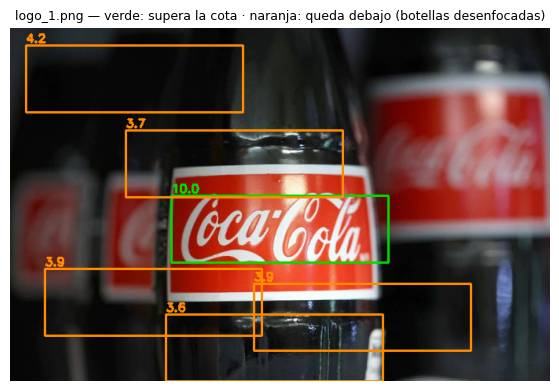

cota de ruido: 4.88 sigmas
sigmas de los 6 primeros picos: 10.0 4.2 3.9 3.9 3.7 3.6


In [19]:
img_l1 = leer(os.path.join(DIR_IMG, 'logo_1.png'))
F_l1 = D.a_gris(img_l1)
bar_l1 = D.barrido_multiescala(F_l1, prep['gris'],
    D.grilla_de_escalas(*D.rango_de_escalas(img_l1.shape, prep['forma'], prep['semi_trazo'])))
b_l1 = max(bar_l1, key=lambda r: r['psr'])
R_l1 = b_l1['R']
med_l1, sig_l1 = D.z_robusto(R_l1)
zmin_l1 = D.cota_de_ruido(R_l1.size)
w_l1, h_l1 = b_l1['caja'][2], b_l1['caja'][3]

ys, xs = np.nonzero(R_l1 > R_l1.mean())
vals = R_l1[ys, xs]
orden = np.argsort(-vals)[:6000]
picos_l1 = D.nms([{'score': float(vals[i]), 'caja': (int(xs[i]), int(ys[i]), w_l1, h_l1)}
                  for i in orden])
z_l1 = (np.array([d['score'] for d in picos_l1]) - med_l1) / sig_l1

out = img_l1.copy()
for d, zz in zip(picos_l1[:6], z_l1[:6]):
    x, y, w, h = d['caja']
    col = (0, 220, 0) if zz >= zmin_l1 else (0, 140, 255)
    cv.rectangle(out, (x, y), (x + w, y + h), col, 2)
    cv.putText(out, f'{zz:.1f}', (x, max(12, y - 4)), cv.FONT_HERSHEY_SIMPLEX, 0.5, col, 2)
mostrar(out, 'logo_1.png — verde: supera la cota · naranja: queda debajo (botellas desenfocadas)')
print(f'cota de ruido: {zmin_l1:.2f} sigmas')
print('sigmas de los 6 primeros picos:', ' '.join(f'{v:.1f}' for v in z_l1[:6]))

## 15. Conclusiones

**Lo que pedía la consigna**

| Ítem | Pedido | Obtenido |
|---|---|---|
| 1 (4 pts) | una detección en cada imagen, sin falsos positivos | **7/7**, 0 falsos positivos |
| 2 (4 pts) | múltiples detecciones en `coca_multi.png`, mismo template | **17/17** logos completos, 0 falsos positivos |
| 3 (2 pts) | generalizar a todas las imágenes | la misma llamada corre sobre las 7 |
| — | bounding boxes con nivel de confianza | en todas las figuras |
| — | parámetros automáticos | tabla de la sección 8 |

**Lo que costó resolver**

1. **La polaridad.** El template es oscuro sobre claro y seis de las siete imágenes tienen el logo
   claro sobre oscuro. Se resuelve con `|NCC|`, que es invariante al signo, y el signo del pico
   informa la polaridad de yapa.

2. **La NCC degenerada.** `TM_CCOEFF_NORMED` devuelve 1.0 sobre fondo plano porque divide 0/0. El
   piso de varianza atado a la energía del template lo corrige sin romper la normalización.

3. **La comparabilidad entre escalas.** El máximo crudo favorece sistemáticamente la escala más
   chica. El PSR, al normalizar contra la propia distribución de cada mapa, sí es comparable.

4. **Los márgenes del template**, que deformaban el aspecto un 41 % y arruinaban silenciosamente
   todo el barrido multiescala.

**La decisión de diseño principal**

Ningún detector único resuelve las siete imágenes. SIFT falla donde el logo es chico y repetido
(`coca_multi`); la correlación falla donde hay deformación de perspectiva (`coca_logo_2`, la lata).
La fusión no es un recurso para tapar agujeros: **es la respuesta a que el conjunto de prueba
contiene deliberadamente los dos regímenes**, y la regla que elige entre uno y otro se mide sobre
los inliers de RANSAC, sin mirar el resultado.
